# R3b — Supervisor LoRA con la ROI generada por YOLO (cascada completa)

R2c midió el supervisor con la zona **perfecta** (la caja anotada): AUC 0.753, falsas alarmas 12/30. Ese es un techo. Aquí el supervisor recibe la zona que encontró **R3a** (YOLO + ByteTrack + reglas), que puede estar corrida, ser demasiado grande o no contener el choque.

*Analogía:* en R2c el guardia revisaba exactamente la cámara correcta porque alguien se la señalaba con el dedo. Ahora se la señala la alarma automática, que a veces apunta un poco al lado.

**Qué se compara (mismas 60 ventanas, mismo LoRA `exp_ebfa594f/final`):**

| Condición | De dónde sale |
|---|---|
| LoRA + ROI oráculo | CSV de R2c (techo) |
| **LoRA + ROI YOLO** | este notebook |
| Base + ROI YOLO | este notebook (opcional) |
| **Cascada**: alerta del paso 2 **y** el LoRA dice "sí" | R3a + este notebook |

Todo el código del supervisor (recorte, muestreo, prompt, `juzgar`, `prob_incidente`) es **copia literal de R2c**; lo único que cambia es la columna `roi`. Antes de evaluar se **verifica** que con la ROI oráculo se reproducen las P(sí) del CSV de R2c.

**Requisito:** haber corrido **R3a v2** (genera `r3_ebfa594f/rois_yolo_ebfa594f.csv` y `resumen_r3a.json` con `formato_roi = cxcywh`). Si la ROI es de v1, el notebook se detiene. Usa la T4.

## 0. Instalación (igual que R2c)

In [ ]:
%pip install -q "transformers>=4.51" accelerate "qwen-vl-utils[decord]" bitsandbytes peft huggingface_hub opencv-python-headless pandas matplotlib scikit-learn "kaggle>=1.7"

In [ ]:
# ===== 1. Configuración, Drive y rutas =====
import os, re, json, time, glob, zipfile, random, shutil, subprocess, io, math
import torch, pandas as pd, numpy as np, cv2
import matplotlib.pyplot as plt
from IPython.display import display

assert torch.cuda.is_available(), "No hay GPU: Entorno de ejecución → Cambiar tipo de entorno → T4 GPU"
from google.colab import drive
drive.mount("/content/drive")

HUELLA = "ebfa594f"
COMPARAR_BASE = True     # también evalúa el modelo base con ROI YOLO (~10 min más)
N_VERIFICACION = 8       # ventanas para comprobar que se reproduce R2c con la ROI oráculo

DIR_PERSISTENTE = "/content/drive/MyDrive/roadvision"
DIR_LOCAL = "/content/datos_roadvision"
DIR_ACC = os.path.join(DIR_LOCAL, "accident")
DIR_RESULTADOS = os.path.join(DIR_PERSISTENTE, "resultados_qwen")
DIR_R3 = os.path.join(DIR_RESULTADOS, f"r3_{HUELLA}")
DIR_LORA_FINAL = os.path.join(DIR_PERSISTENTE, "lora_supervisor_roi", f"exp_{HUELLA}", "final")
DIR_CLIPS_YOLO = os.path.join(DIR_LOCAL, "clips_test_roi_yolo")
DIR_CLIPS_VERIF = os.path.join(DIR_LOCAL, "clips_verificacion_oraculo")
for d in (DIR_ACC, DIR_CLIPS_YOLO, DIR_CLIPS_VERIF):
    os.makedirs(d, exist_ok=True)
SEMILLA = 0
for r in [DIR_LORA_FINAL, f"{DIR_R3}/rois_yolo_{HUELLA}.csv", f"{DIR_RESULTADOS}/test_roi_lora_{HUELLA}.csv"]:
    assert os.path.exists(r), f"Falta {r}"
print("LoRA:", DIR_LORA_FINAL)

# La ROI tiene que venir de R3a v2 (formato cx, cy, w, h). R3a v1 la guardaba como x, y, w, h.
import hashlib
info_r3a = json.load(open(f"{DIR_R3}/resumen_r3a.json"))
print("R3a:", {k: info_r3a.get(k) for k in ("version", "imgsz", "conf", "formato_roi", "auc_test", "alertas_pos", "alertas_neg")})
assert info_r3a.get("formato_roi") == "cxcywh", (
    "rois_yolo es de R3a v1 (formato xywh). Corre R3a v2 primero y vuelve a correr este notebook.")
ROI_HASH = hashlib.md5(open(f"{DIR_R3}/rois_yolo_{HUELLA}.csv", "rb").read()).hexdigest()[:8]
print("Huella de la ROI YOLO:", ROI_HASH, "(los recortes y resultados se guardan con esta huella; si cambia la ROI, no se reusan)")

Mounted at /content/drive
LoRA: /content/drive/MyDrive/roadvision/lora_supervisor_roi/exp_ebfa594f/final
R3a: {'version': 'v2', 'imgsz': 960, 'conf': 0.1, 'formato_roi': 'cxcywh', 'auc_test': 0.636, 'alertas_pos': '7/30', 'alertas_neg': '2/30'}
Huella de la ROI YOLO: 5bd154ce (los recortes y resultados se guardan con esta huella; si cambia la ROI, no se reusan)


In [ ]:
# ===== 2. Ventanas: resultados de R2c (oráculo) + ROI de R3a =====
parse = lambda s: tuple(float(x) for x in str(s).strip('()[] ').split(','))
wid = lambda df: df['video'] + '|' + df['inicio'].round(3).astype(str)

or_lora = pd.read_csv(f"{DIR_RESULTADOS}/test_roi_lora_{HUELLA}.csv")
or_base = pd.read_csv(f"{DIR_RESULTADOS}/test_roi_base_{HUELLA}.csv")
r3a = pd.read_csv(f"{DIR_R3}/rois_yolo_{HUELLA}.csv")
for df in (or_lora, or_base):
    df['wid'] = wid(df)

base_cols = ['wid', 'clase', 'inicio', 'fin', 't_rel', 'video', 'ruta_rel', 't_choque', 'tipo_real', 'dominio', 'roi']
TEST = or_lora[base_cols].merge(r3a[['wid', 'roi_yolo', 'score', 'alerta', 'fuente', 't_evento', 'iou_recorte', 'choque_dentro']],
                                on='wid', how='left', validate='1:1')
assert TEST['roi_yolo'].notna().all(), 'Hay ventanas sin ROI de R3a: ¿corriste R3a con las mismas ventanas?'
TEST['roi'] = TEST['roi'].map(parse)
TEST['roi_yolo'] = TEST['roi_yolo'].map(parse)
TEST['ruta'] = TEST['ruta_rel'].map(lambda n: os.path.join(DIR_ACC, n))
TEST['contexto'] = None
print(f"{len(TEST)} ventanas · {TEST.clase.value_counts().to_dict()} · alertas del paso 2: {int(TEST.alerta.sum())}")

60 ventanas · {'positiva': 30, 'negativa': 30} · alertas del paso 2: 9


In [ ]:
# ===== 3. Videos (si la sesión de R3a ya los dejó en /content, no descarga nada) =====
faltan = sorted(set(TEST.loc[~TEST.ruta.map(os.path.exists), 'ruta_rel']))
print('Videos que faltan:', len(faltan))
if faltan:
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    ZIP = next(iter([z for z in glob.glob(os.path.join(DIR_LOCAL, "*.zip")) if zipfile.is_zipfile(z)]), None)
    if ZIP is None:
        !kaggle datasets download picekl/accident -p {DIR_LOCAL}
        ZIP = glob.glob(os.path.join(DIR_LOCAL, "*.zip"))[0]
    with zipfile.ZipFile(ZIP) as zf:
        miembros = set(zf.namelist())
        for n in faltan:
            assert n in miembros, f'{n} no está en el ZIP'
            zf.extract(n, DIR_ACC)
assert TEST.ruta.map(os.path.exists).all()
print('Videos listos ✔')

Videos que faltan: 30
Dataset URL: https://www.kaggle.com/datasets/picekl/accident
License(s): CC-BY-NC-SA-4.0
100% 15.6G/15.6G [14:46<00:00, 18.9MB/s]

Videos listos ✔


## 4. Funciones de R2c (copia literal): muestreo, recorte, parser, prompt, P(sí)

In [ ]:
# --- R2c, sección 4 (sin preparar_frames) ---
def info_video(ruta_video):
    cap = cv2.VideoCapture(ruta_video)
    fps = cap.get(cv2.CAP_PROP_FPS) or 0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ancho, alto = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return fps, total, (total / fps if fps > 0 else 0), ancho, alto


FPS_VIDEO = 2.0
MAX_FRAMES = 16
MAX_PIXELES_VIDEO = 360 * 420

TIPOS = {"frontal", "alcance", "en_t", "roce_lateral", "un_vehiculo", "otro", "ninguno"}
MAPEO_TIPO = {   # clase de ACCIDENT (inglés) → clase del JSON
    "head-on": "frontal", "head_on": "frontal", "headon": "frontal",
    "rear-end": "alcance", "rear_end": "alcance", "rearend": "alcance",
    "t-bone": "en_t", "t_bone": "en_t", "tbone": "en_t",
    "sideswipe": "roce_lateral", "side-swipe": "roce_lateral",
    "single": "un_vehiculo", "single-vehicle": "un_vehiculo", "single_vehicle": "un_vehiculo",
}


def tipo_json(valor):
    v = str(valor).strip().lower()
    return MAPEO_TIPO.get(v, MAPEO_TIPO.get(v.replace(" ", "-"), "otro"))



ZOOM, MIN_LADO_FRAC, LADO_SALIDA = 3.0, 0.25, 392


def caja_recorte(roi, ancho, alto, jitter=None):
    """(x0, y0, lado) en píxeles del cuadrado a recortar."""
    corto = min(ancho, alto)
    if roi is None:
        return None
    cx, cy, bw, bh = roi
    lado = max(bw * ancho, bh * alto) * ZOOM
    lado = min(max(lado, MIN_LADO_FRAC * corto), corto)
    cxp, cyp = cx * ancho, cy * alto
    if jitter is not None:
        dx, dy, esc = jitter
        lado = min(max(lado * esc, MIN_LADO_FRAC * corto), corto)
        cxp, cyp = cxp + dx * lado, cyp + dy * lado
    x0 = int(min(max(cxp - lado / 2, 0), ancho - lado))
    y0 = int(min(max(cyp - lado / 2, 0), alto - lado))
    return x0, y0, int(lado)


def muestrear_ventana(ruta, inicio, fin, carpeta, roi=None, jitter=None, max_frames=MAX_FRAMES):
    """Lee la ventana en orden, recorta la región y guarda hasta max_frames jpg de LADO_SALIDA×LADO_SALIDA."""
    fps, total, dur, ancho, alto = info_video(ruta)
    largo = fin - inicio
    n = int(min(max_frames, max(2, largo * FPS_VIDEO)))
    n -= n % 2
    tiempos = [inicio + i * largo / n for i in range(n)]
    caja = caja_recorte(roi, ancho, alto, jitter)
    if caja is None:   # sin ROI: frame completo con el mismo presupuesto de píxeles
        escala = min(1.0, (LADO_SALIDA ** 2 / max(1, ancho * alto)) ** 0.5)
        tam = (max(28, int(ancho * escala)), max(28, int(alto * escala)))
    shutil.rmtree(carpeta, ignore_errors=True); os.makedirs(carpeta, exist_ok=True)
    cap = cv2.VideoCapture(ruta)
    cap.set(cv2.CAP_PROP_POS_MSEC, max(0.0, inicio - 0.5) * 1000)
    rutas, k = [], 0
    while k < len(tiempos) and cap.grab():
        t = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000
        if t + 1e-3 >= tiempos[k]:
            ok, img = cap.retrieve()
            if ok:
                if caja is not None:
                    x0, y0, lado = caja
                    img = cv2.resize(img[y0:y0 + lado, x0:x0 + lado], (LADO_SALIDA, LADO_SALIDA),
                                     interpolation=cv2.INTER_CUBIC if lado < LADO_SALIDA else cv2.INTER_AREA)
                else:
                    img = cv2.resize(img, tam, interpolation=cv2.INTER_AREA)
                r = os.path.join(carpeta, f"{len(rutas):03d}.jpg")
                cv2.imwrite(r, img)
                rutas.append(r)
            k += 1
            while k < len(tiempos) and t + 1e-3 >= tiempos[k]:
                k += 1
    cap.release()
    if len(rutas) % 2:
        rutas = rutas[:-1]
    return rutas, (len(rutas) / largo if largo > 0 else FPS_VIDEO), largo


In [ ]:
# --- R2c, funciones de apoyo ---
from qwen_vl_utils import process_vision_info

_CAP_OK = True   # se apaga solo si esta versión de transformers no reconoce cap_pixels_per_frame


def preguntar(contenido, max_new_tokens=256, fps_video=None):
    """Envía un mensaje (lista de partes image/video/text) y devuelve (texto, segundos, entradas)."""
    global _CAP_OK
    mensajes = [{"role": "user", "content": contenido}]
    texto = procesador.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    try:
        imgs, vids, video_kwargs = process_vision_info(mensajes, return_video_kwargs=True)
    except TypeError:
        imgs, vids = process_vision_info(mensajes)
        video_kwargs = {}

    extra = {}
    if vids:
        fps = (video_kwargs or {}).get("fps")
        if isinstance(fps, (list, tuple)):
            fps = fps[0] if fps else None
        if fps_video is not None:          # cuando mandamos frames sueltos, el fps real lo sabemos nosotros
            fps = fps_video
        if fps is not None:
            extra["fps"] = float(fps)
        if _CAP_OK:
            extra["cap_pixels_per_frame"] = True

    try:
        entradas = procesador(text=[texto], images=imgs or None, videos=vids or None, padding=True,
                              return_tensors="pt", **extra)
    except TypeError:
        _CAP_OK = False
        extra.pop("cap_pixels_per_frame", None)
        entradas = procesador(text=[texto], images=imgs or None, videos=vids or None, padding=True,
                              return_tensors="pt", **extra)
    entradas = entradas.to(modelo.device)

    torch.cuda.synchronize()
    t0 = time.time()
    with torch.no_grad():
        salida = modelo.generate(**entradas, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    segundos = time.time() - t0
    nuevos = salida[:, entradas["input_ids"].shape[1]:]
    respuesta = procesador.batch_decode(nuevos, skip_special_tokens=True)[0].strip()
    return respuesta, segundos, entradas


def parece_basura(texto):
    t = texto.strip()
    return len(t) == 0 or len(set(t)) <= 3 or t.count("!") > len(t) * 0.5


def _primer_json(t):
    inicio = min([i for i in (t.find("{"), t.find("[")) if i >= 0], default=-1)
    if inicio < 0:
        return None
    for fin in range(len(t), inicio, -1):
        try:
            return json.loads(t[inicio:fin])
        except json.JSONDecodeError:
            continue
    return None


def _reparar_lineas(t):
    """Pone comillas a valores que no son JSON válido: "clave": 2011-07-04 09:51:13,  ->  "clave": "2011-07-04 09:51:13","""
    salida = []
    for linea in t.splitlines():
        m = re.match(r'^(\s*"[^"]+"\s*:\s*)(.+?)(\s*,?\s*)$', linea)
        if m:
            valor = m.group(2)
            try:
                json.loads(valor)
            except json.JSONDecodeError:
                valor = json.dumps(valor.strip().strip('"'), ensure_ascii=False)
            linea = m.group(1) + valor + m.group(3)
        salida.append(linea)
    return "\n".join(salida)


def extraer_json(texto):
    """Devuelve (objeto_o_None, reparado: bool)."""
    t = re.sub(r"```(?:json)?", "", texto)
    obj = _primer_json(t)
    if obj is not None:
        return obj, False
    obj = _primer_json(_reparar_lineas(t))
    return obj, obj is not None


TIPOS = {"choque_vehiculos", "atropello", "moto_caida", "vehiculo_detenido", "otro", "ninguno"}
FRASES_PLANTILLA = {"una oración en español", "una oracion en español", ""}


def _a_bool(x):
    if isinstance(x, bool):
        return x
    if isinstance(x, str) and x.strip().lower() in ("true", "false", "sí", "si", "no"):
        return x.strip().lower() in ("true", "sí", "si")
    return None


def normalizar_juicio(datos, duracion_s):
    """Valida campos y anota qué estaba mal. Devuelve un dict limpio."""
    problemas = []
    inc = _a_bool(datos.get("incidente"))
    if inc is None:
        problemas.append("incidente")
    tipo = str(datos.get("tipo", "")).strip().lower()
    if tipo not in TIPOS:
        problemas.append("tipo"); tipo = "otro" if inc else "ninguno"
    seg = datos.get("segundo_aprox")
    if not isinstance(seg, (int, float)) or isinstance(seg, bool) or not (0 <= seg <= duracion_s + 1):
        if seg is not None:
            problemas.append("segundo_aprox")
        seg = None
    fija = _a_bool(datos.get("camara_fija"))
    desc = str(datos.get("descripcion", "")).strip()
    if desc.lower() in FRASES_PLANTILLA:
        problemas.append("descripcion")
    return {"incidente": inc, "tipo": tipo, "segundo_aprox": seg, "camara_fija": fija,
            "descripcion": desc, "campos_malos": ",".join(problemas)}


# Prueba rápida del parser con la respuesta real que falló el 22 de octubre
_ejemplo = '```json\n{\n  "incidente": true,\n  "tipo": "atropello",\n  "segundo_aprox": 2011-07-04 09:51:13,\n  "camara_fija": false,\n  "descripcion": "una oración en español"\n}\n```'
_obj, _rep = extraer_json(_ejemplo)
print("reparado:", _rep, "→", normalizar_juicio(_obj, duracion_s=12))

reparado: True → {'incidente': True, 'tipo': 'atropello', 'segundo_aprox': None, 'camara_fija': False, 'descripcion': 'una oración en español', 'campos_malos': 'segundo_aprox,descripcion'}


## 5. Modelo: Qwen2.5-VL-3B en 4 bits + LoRA final de R2c

In [ ]:
import transformers
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig
from peft import PeftModel, prepare_model_for_kbit_training
from qwen_vl_utils import process_vision_info

MODELO_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
MIN_PIX, MAX_PIX = 256 * 28 * 28, 1024 * 28 * 28
print("transformers", transformers.__version__)
cuant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                           bnb_4bit_compute_dtype=torch.float16)
t0 = time.time()
modelo = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODELO_ID, quantization_config=cuant, device_map={"": 0}, attn_implementation="sdpa")
try:
    procesador = AutoProcessor.from_pretrained(MODELO_ID, size={"shortest_edge": MIN_PIX, "longest_edge": MAX_PIX})
except (TypeError, ValueError):
    procesador = AutoProcessor.from_pretrained(MODELO_ID, min_pixels=MIN_PIX, max_pixels=MAX_PIX)
# Mismo estado numérico que en la evaluación de R2c (capas normales en fp32 tras prepare_model_for_kbit_training)
modelo = prepare_model_for_kbit_training(modelo, use_gradient_checkpointing=True,
                                         gradient_checkpointing_kwargs={"use_reentrant": False})
modelo = PeftModel.from_pretrained(modelo, DIR_LORA_FINAL, is_trainable=False)
modelo.eval(); modelo.config.use_cache = True
print(f"Cargado en {time.time()-t0:.0f} s · VRAM {torch.cuda.memory_allocated()/1e9:.1f} GB")

transformers 5.22.1


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Cargado en 117 s · VRAM 3.2 GB


In [ ]:
# --- R2c, prompt y P(sí) ---
TIPOS = {"frontal", "alcance", "en_t", "roce_lateral", "un_vehiculo", "otro", "ninguno"}

PROMPT_INCIDENTE = (
    "Eres operador de un centro de monitoreo de tráfico (C5). El sistema marcó esta zona de una cámara "
    "de vigilancia. Mira el video de la zona ({dur:.0f} segundos) y decide si en ella ocurre un choque.\n"
    "Responde SOLO con un objeto JSON con estas claves, en este orden:\n"
    "- incidente: true o false\n"
    "- tipo: una de frontal, alcance, en_t, roce_lateral, un_vehiculo, otro, ninguno "
    "(alcance = un vehículo pega por detrás a otro; en_t = un vehículo pega en el costado de otro; "
    "roce_lateral = dos vehículos se rozan de lado; un_vehiculo = choca solo contra un objeto; "
    "ninguno si incidente es false)\n"
    "- segundo_aprox: segundo en que ocurre el choque, entre 0 y {dur:.0f}; null si no hay choque\n"
    "Ignora fechas, horas y logotipos sobreimpresos.\n"
    'Ejemplo de formato con valores inventados: {{"incidente": false, "tipo": "ninguno", "segundo_aprox": null}}'
)


def mensaje_usuario(v):
    return {"role": "user", "content": [
        {"type": "video", "video": [f"file://{r}" for r in v["frames"]]},
        {"type": "text", "text": PROMPT_INCIDENTE.format(dur=v["dur"])}]}


def procesar(texto, usuario, fps):
    _, vids, _ = process_vision_info([usuario], return_video_kwargs=True)
    extra = {"fps": float(fps)}
    if _CAP_OK:
        extra["cap_pixels_per_frame"] = True
    try:
        return procesador(text=[texto], videos=vids, return_tensors="pt", **extra)
    except TypeError:
        extra.pop("cap_pixels_per_frame", None)
        return procesador(text=[texto], videos=vids, return_tensors="pt", **extra)


def juzgar(v):
    """Genera la respuesta completa (para tipo y segundo)."""
    usuario = mensaje_usuario(v)
    texto = procesador.apply_chat_template([usuario], tokenize=False, add_generation_prompt=True)
    ent = procesar(texto, usuario, v["fps_ef"]).to(modelo.device)
    t0 = time.time()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        sal = modelo.generate(**ent, max_new_tokens=60, do_sample=False)
    resp = procesador.batch_decode(sal[:, ent["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()
    datos, reparado = extraer_json(resp)
    if isinstance(datos, dict):
        r = normalizar_juicio(datos, v["dur"]); r["formato"] = "reparado" if reparado else "ok"
    else:
        r = {"incidente": None, "tipo": "sin_json", "segundo_aprox": None, "formato": "irrecuperable"}
    r.update({"segundos": round(time.time() - t0, 2), "respuesta_cruda": resp})
    return r


# --- P(incidente = true): una sola pasada, sin generar
_A = procesador.tokenizer.encode('{"incidente": true', add_special_tokens=False)
_B = procesador.tokenizer.encode('{"incidente": false', add_special_tokens=False)
_J = next(i for i, (a, b) in enumerate(zip(_A, _B)) if a != b)
PREFIJO, TOK_SI, TOK_NO = procesador.tokenizer.decode(_A[:_J]), _A[_J], _B[_J]
print(f"Prefijo de respuesta: {PREFIJO!r} · token 'true' = {TOK_SI} · token 'false' = {TOK_NO}")


def prob_incidente(v):
    usuario = mensaje_usuario(v)
    texto = procesador.apply_chat_template([usuario], tokenize=False, add_generation_prompt=True) + PREFIJO
    ent = procesar(texto, usuario, v["fps_ef"]).to(modelo.device)
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        logits = modelo(**ent).logits[0, -1, [TOK_SI, TOK_NO]].float()
    return torch.softmax(logits, -1)[0].item()

# --- R2c, P(sí) con reintentos si fp16 se desborda ---
PROB_FALLIDAS = []   # ventanas donde fp16 se desbordó en todos los intentos


def prob_incidente(v):
    """P(incidente = true). Si fp16 se desborda, reintenta sin autocast y luego con la mitad de frames;
    si todo falla, devuelve 0.5 (no sabe) y lo anota."""
    intentos = [(v, True), (v, False)]
    if len(v["frames"]) >= 4:
        mitad = v.copy()
        mitad["frames"] = v["frames"][::2][: (len(v["frames"][::2]) // 2) * 2]
        mitad["fps_ef"] = v["fps_ef"] / 2
        intentos.append((mitad, False))
    for vv, con_autocast in intentos:
        usuario = mensaje_usuario(vv)
        texto = procesador.apply_chat_template([usuario], tokenize=False, add_generation_prompt=True) + PREFIJO
        ent = procesar(texto, usuario, vv["fps_ef"]).to(modelo.device)
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=con_autocast):
            logits = modelo(**ent).logits[0, -1, [TOK_SI, TOK_NO]].float()
        if torch.isfinite(logits).all():
            return torch.softmax(logits, -1)[0].item()
    PROB_FALLIDAS.append(v["video"])
    return 0.5

Prefijo de respuesta: '{"incidente":' · token 'true' = 830 · token 'false' = 895


## 6. Verificación: ¿se reproduce R2c con la ROI oráculo?

Si con la **misma** ROI las P(sí) no salen iguales a las del CSV de R2c, algo cambió (versión de librerías, LoRA equivocado, frames distintos) y la comparación oráculo vs YOLO no sería justa.

In [ ]:
# ===== 6. Verificación =====
ver = pd.concat([TEST[TEST.clase == 'positiva'].head(N_VERIFICACION // 2),
                 TEST[TEST.clase == 'negativa'].head(N_VERIFICACION // 2)])
p_csv = or_lora.set_index('wid')['p_si']
filas = []
for i, v in ver.iterrows():
    fr, fps_ef, dur = muestrear_ventana(v['ruta'], v['inicio'], v['fin'], os.path.join(DIR_CLIPS_VERIF, f've{i:05d}'), v['roi'])
    vv = v.copy(); vv['frames'], vv['fps_ef'], vv['dur'] = fr, fps_ef, dur
    fila_r2c = or_lora.set_index('wid').loc[v['wid']]
    filas.append(dict(wid=v['wid'], clase=v['clase'], p_ahora=prob_incidente(vv), p_r2c=p_csv[v['wid']],
                      frames_ahora=len(fr), frames_r2c=int(round(fila_r2c['fps_ef'] * fila_r2c['dur'])),
                      fps_ahora=round(fps_ef, 3), fps_r2c=round(float(fila_r2c['fps_ef']), 3)))
ver_df = pd.DataFrame(filas); ver_df['dif'] = (ver_df.p_ahora - ver_df.p_r2c).abs()
display(ver_df.round(3))
print(f"Diferencia máxima: {ver_df.dif.max():.3f}")
malas = ver_df[ver_df.dif > 0.05]
if len(malas):
    print(f"{len(malas)} de {len(ver_df)} no coinciden. Si frames_ahora ≠ frames_r2c, la diferencia viene de leer el video, no del modelo.")
if len(malas) > 1 or ver_df.dif.max() > 0.3:
    print("⚠️  No se reproduce R2c (> 0.05). Revisa versión de transformers/peft y que el LoRA sea exp_ebfa594f/final.")
else:
    print("✔ Se reproduce R2c (a lo más una ventana distinta): la comparación oráculo vs YOLO es justa.")

,wid,clase,p_ahora,p_r2c,frames_ahora,frames_r2c,fps_ahora,fps_r2c,dif
0,QbTAfMWdSN0_00|6.411,positiva,0.734,0.734,16,16,2.000,2.000,0.000
1,sKJdbm04q6U_00|5.014,positiva,0.593,0.593,16,16,2.000,2.000,0.000
2,Czp_f_DrRB8_00|6.939,positiva,0.881,0.882,16,16,2.000,2.000,0.002
3,aRQeSqO9Ri4_00|3.034,positiva,0.593,0.846,14,16,1.750,2.000,0.253
4,QbTAfMWdSN0_00|0.0,negativa,0.818,0.818,10,10,1.791,1.791,0.000
5,sKJdbm04q6U_00|0.0,negativa,0.626,0.622,14,14,1.909,1.909,0.004
6,Czp_f_DrRB8_00|0.0,negativa,0.367,0.367,14,14,1.768,1.768,0.000
7,aRQeSqO9Ri4_00|0.0,negativa,0.722,0.719,8,8,1.669,1.669,0.003


Diferencia máxima: 0.253
1 de 8 no coinciden. Si frames_ahora ≠ frames_r2c, la diferencia viene de leer el video, no del modelo.
✔ Se reproduce R2c (a lo más una ventana distinta): la comparación oráculo vs YOLO es justa.


60 ventanas recortadas en 33 s


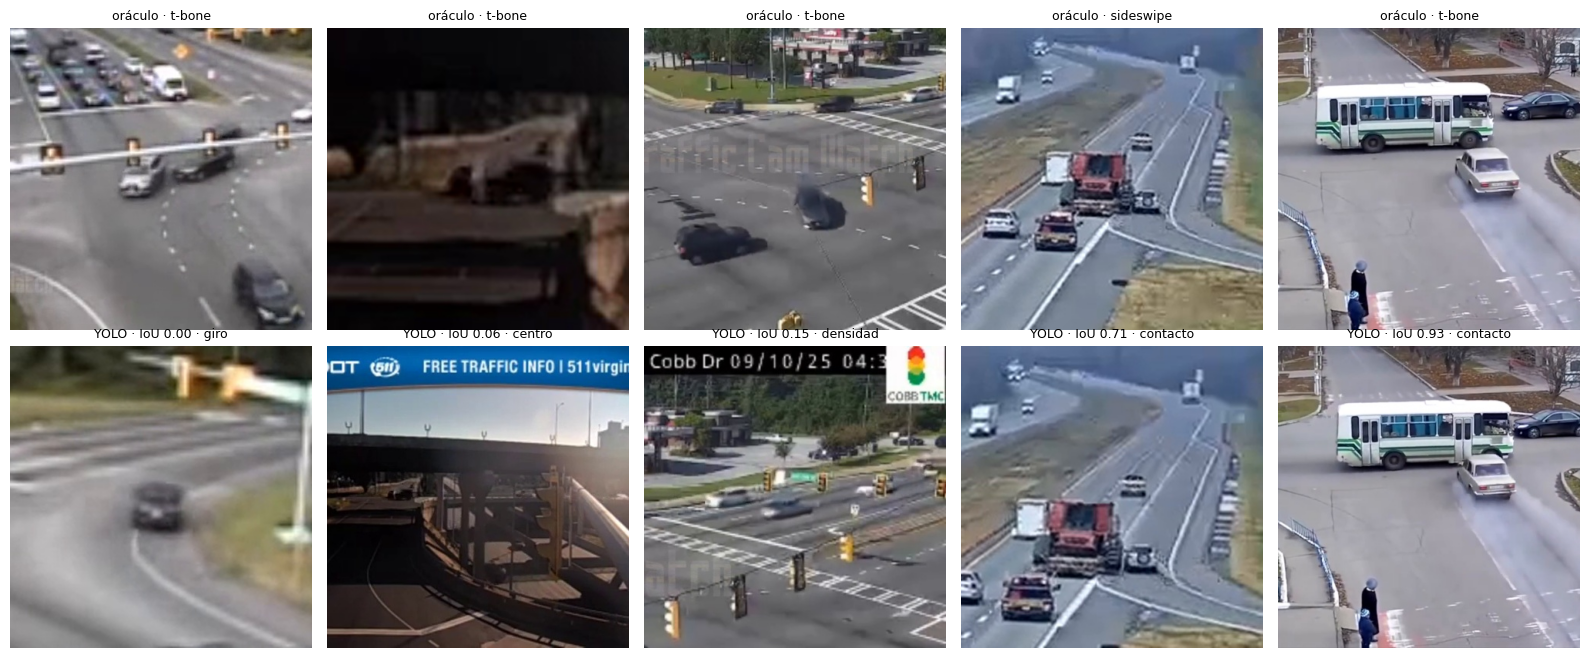

In [ ]:
# ===== 7. Frames recortados con la ROI de YOLO =====
TY = TEST.copy()
TY['roi'] = TY['roi_yolo']            # ← lo único que cambia respecto a R2c
rutas, fpss, durs = [], [], []
t0 = time.time()
for i, v in TY.iterrows():
    carpeta = os.path.join(DIR_CLIPS_YOLO, ROI_HASH, f"ty{i:05d}")
    hecho = os.path.join(carpeta, "_ok.json")
    if os.path.exists(hecho):
        info = json.load(open(hecho))
    else:
        r, fps_ef, largo = muestrear_ventana(v["ruta"], v["inicio"], v["fin"], carpeta, v["roi"])
        info = {"frames": r, "fps": fps_ef, "dur": largo}
        json.dump(info, open(hecho, "w"))
    rutas.append(info["frames"]); fpss.append(info["fps"]); durs.append(info["dur"])
TY["frames"], TY["fps_ef"], TY["dur"] = rutas, fpss, durs
assert (TY.frames.map(len) >= 2).all()
print(f"{len(TY)} ventanas recortadas en {time.time()-t0:.0f} s")

# Vistazo: mismo frame con ROI oráculo (arriba, de R2c) y ROI YOLO (abajo)
muestras = TY[TY.clase == 'positiva'].sort_values('iou_recorte').iloc[[0, 5, 15, 25, -1]]
fig, ejes = plt.subplots(2, len(muestras), figsize=(3.2 * len(muestras), 6.6), squeeze=False)
for j, (i, v) in enumerate(muestras.iterrows()):
    k = min(len(v['frames']) - 1, int(v['t_rel'] * v['fps_ef']))
    vo = TEST.loc[i]
    fo, _, _ = muestrear_ventana(vo['ruta'], vo['t_choque'] - 0.25, vo['t_choque'] + 0.75,
                                 os.path.join(DIR_CLIPS_VERIF, f'vis{i:05d}'), vo['roi'], max_frames=2)
    ejes[0, j].imshow(cv2.imread(fo[0])[..., ::-1]); ejes[0, j].set_title(f"oráculo · {v['tipo_real']}", fontsize=9)
    ejes[1, j].imshow(cv2.imread(v['frames'][k])[..., ::-1])
    ejes[1, j].set_title(f"YOLO · IoU {v['iou_recorte']:.2f} · {v['fuente']}", fontsize=9)
for a in ejes.flat: a.axis('off')
fig.tight_layout(); fig.savefig(f"{DIR_R3}/recortes_oraculo_vs_yolo_{ROI_HASH}.png", dpi=120); plt.show()

## 8. Evaluación con ROI YOLO (mismo `juzgar` + `prob_incidente` de R2c)

In [ ]:
# ===== 8. Evaluar =====
def evaluar_yolo(nombre):
    arch = os.path.join(DIR_R3, f"test_roi_yolo_{nombre}_{HUELLA}_{ROI_HASH}.csv")
    if os.path.exists(arch):
        print('Leído de Drive:', arch); return pd.read_csv(arch)
    modelo.eval(); modelo.config.use_cache = True
    filas = []
    for k, (i, v) in enumerate(TY.iterrows()):
        r = juzgar(v)
        t0 = time.time(); r["p_si"] = prob_incidente(v); r["segundos_p"] = round(time.time() - t0, 2)
        filas.append({**v.drop(labels=["frames", "contexto"], errors="ignore").to_dict(),
                      **{(f"pred_{kk}" if kk in ("incidente", "tipo", "segundo_aprox") else kk): x for kk, x in r.items()}})
        if (k + 1) % 10 == 0:
            print(f"  {nombre}: {k+1}/{len(TY)}", flush=True)
    res = pd.DataFrame(filas)
    res.to_csv(arch, index=False)
    return res

res_lora_y = evaluar_yolo("lora")
if COMPARAR_BASE:
    with modelo.disable_adapter():
        res_base_y = evaluar_yolo("base")
print('Fallos de fp16 (P=0.5):', PROB_FALLIDAS)

  lora: 10/60
  lora: 20/60
  lora: 30/60
  lora: 40/60
  lora: 50/60
  lora: 60/60
  base: 10/60
  base: 20/60
  base: 30/60
  base: 40/60
  base: 50/60
  base: 60/60
Fallos de fp16 (P=0.5): []


## 9. Comparación y pruebas pareadas

Mismas pruebas que R2d: **McNemar exacto** para conteos y **DeLong pareado** para el AUC. Aquí la pregunta es *¿cuánto se pierde por usar la ROI de YOLO en vez de la perfecta?*

In [ ]:
# ===== 9. Métricas =====
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import binomtest, norm

def b(s): return s.map(lambda x: str(x).strip().lower() == 'true')

def metricas(res):
    y = (res.clase == 'positiva').values
    pred = b(res.pred_incidente).values
    det = res[y & pred]
    tipo_ok = (det.pred_tipo == det.tipo_real.map(tipo_json)).mean() if len(det) else np.nan
    con_t = det[det.pred_segundo_aprox.notna()]
    err = (pd.to_numeric(con_t.pred_segundo_aprox) - con_t.t_rel).abs()
    return {'AUC': round(roc_auc_score(y.astype(int), res.p_si), 3),
            'choques detectados': f'{(y & pred).sum()}/{y.sum()}',
            'falsas alarmas': f'{(~y & pred).sum()}/{(~y).sum()}',
            'precision': f'{(y & pred).sum() / max(1, pred.sum()):.0%}',
            'tipo correcto': f'{tipo_ok:.0%}' if tipo_ok == tipo_ok else '—',
            'segundo ±2 s': f'{(err <= 2).mean():.0%}' if len(err) else '—',
            'JSON válido': f"{(res.formato == 'ok').mean():.0%}",
            'latencia generación (s)': f"{res.segundos.median():.1f}"}

def alinear(a, c):
    a = a.copy(); c = c.copy()
    for df in (a, c):
        if 'wid' not in df: df['wid'] = wid(df)
    m = a.merge(c, on='wid', suffixes=('_a', '_c'), validate='1:1')
    assert len(m) == len(a) == len(c)
    return m

def mcnemar(xa, xc):
    bb = int((~xa & xc).sum()); cc = int((xa & ~xc).sum())
    return bb, cc, (binomtest(min(bb, cc), bb + cc, .5).pvalue if bb + cc else 1.0)

def delong(y, S):
    pos, neg = S[:, y == 1], S[:, y == 0]
    psi = (pos[:, :, None] > neg[:, None, :]) + 0.5 * (pos[:, :, None] == neg[:, None, :])
    V10, V01 = psi.mean(2), psi.mean(1)
    return V10.mean(1), np.cov(V10) / pos.shape[1] + np.cov(V01) / neg.shape[1]

tab = {'LoRA + ROI oráculo (R2c)': metricas(or_lora), 'LoRA + ROI YOLO': metricas(res_lora_y)}
if COMPARAR_BASE:
    tab = {'Base + ROI oráculo (R2c)': metricas(or_base), **tab, 'Base + ROI YOLO': metricas(res_base_y)}
tabla = pd.DataFrame(tab); display(tabla)
tabla.to_csv(f"{DIR_R3}/comparacion_oraculo_vs_yolo_{HUELLA}_{ROI_HASH}.csv")

def comparar(a, c, na, nc):
    m = alinear(a, c); y = (m.clase_a == 'positiva').values.astype(int)
    pa, pc = b(m.pred_incidente_a).values, b(m.pred_incidente_c).values
    print(f'\n{na}  →  {nc}')
    for que, msk in (('falsas alarmas', y == 0), ('choques detectados', y == 1)):
        bb, cc, p = mcnemar(pa[msk], pc[msk])
        print(f'  {que}: {pa[msk].sum()} → {pc[msk].sum()}  (solo {na}: {cc}, solo {nc}: {bb}; McNemar p = {p:.3g})')
    auc, cov = delong(y, np.vstack([m.p_si_a.values, m.p_si_c.values]))
    d = auc[1] - auc[0]; se = np.sqrt(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1])
    p = 2 * norm.sf(abs(d / se)) if se > 0 else 1.0
    print(f'  AUC {auc[0]:.3f} → {auc[1]:.3f}  (Δ {d:+.3f}, IC95 {d - 1.96 * se:+.3f} a {d + 1.96 * se:+.3f}, DeLong p = {p:.3g})')
    return dict(de=na, a=nc, auc_de=auc[0], auc_a=auc[1], dif=d, ic_lo=d - 1.96 * se, ic_hi=d + 1.96 * se, p_delong=p)

pruebas = [comparar(or_lora, res_lora_y, 'LoRA oráculo', 'LoRA YOLO')]
if COMPARAR_BASE:
    pruebas.append(comparar(res_base_y, res_lora_y, 'Base YOLO', 'LoRA YOLO'))
pd.DataFrame(pruebas).to_csv(f"{DIR_R3}/pruebas_pareadas_r3b_{HUELLA}_{ROI_HASH}.csv", index=False)

,Base + ROI oráculo (R2c),LoRA + ROI oráculo (R2c),LoRA + ROI YOLO,Base + ROI YOLO
AUC,0.648,0.753,0.653,0.602
choques detectados,28/30,26/30,18/30,26/30
falsas alarmas,26/30,12/30,11/30,20/30
precision,52%,68%,62%,57%
tipo correcto,50%,65%,67%,42%
segundo ±2 s,61%,62%,56%,62%
JSON válido,100%,100%,100%,100%
latencia generación (s),5.6,6.7,5.5,4.4



LoRA oráculo  →  LoRA YOLO
  falsas alarmas: 12 → 11  (solo LoRA oráculo: 4, solo LoRA YOLO: 3; McNemar p = 1)
  choques detectados: 26 → 18  (solo LoRA oráculo: 9, solo LoRA YOLO: 1; McNemar p = 0.0215)
  AUC 0.753 → 0.653  (Δ -0.101, IC95 -0.216 a +0.015, DeLong p = 0.0868)

Base YOLO  →  LoRA YOLO
  falsas alarmas: 20 → 11  (solo Base YOLO: 11, solo LoRA YOLO: 2; McNemar p = 0.0225)
  choques detectados: 26 → 18  (solo Base YOLO: 8, solo LoRA YOLO: 0; McNemar p = 0.00781)
  AUC 0.602 → 0.653  (Δ +0.051, IC95 -0.068 a +0.170, DeLong p = 0.4)


## 10. La cascada completa

En producción el LoRA **solo** ve lo que el paso 2 alertó. Alarma final = `alerta del paso 2` **y** `LoRA dice incidente`.
- Las ventanas sin alerta nunca llegan al supervisor → cuentan como "no".
- Por eso la cascada puede bajar falsas alarmas (dos filtros) pero también perder choques que las reglas no vieron.

In [ ]:
# ===== 10. Cascada =====
y = (res_lora_y.clase == 'positiva').values
al = b(res_lora_y.alerta.astype(str)).values
sup = b(res_lora_y.pred_incidente).values
final = al & sup
casc = pd.DataFrame({
    'Paso 2 solo (reglas)': [f'{(y & al).sum()}/{y.sum()}', f'{(~y & al).sum()}/{(~y).sum()}'],
    'LoRA solo (ROI YOLO, sin filtro)': [f'{(y & sup).sum()}/{y.sum()}', f'{(~y & sup).sum()}/{(~y).sum()}'],
    'Cascada (paso 2 Y LoRA)': [f'{(y & final).sum()}/{y.sum()}', f'{(~y & final).sum()}/{(~y).sum()}'],
}, index=['choques detectados', 'falsas alarmas'])
display(casc); casc.to_csv(f"{DIR_R3}/cascada_{HUELLA}_{ROI_HASH}.csv")
print(f'Ventanas que llegan al supervisor: {al.sum()}/{len(al)}')

# ¿Importa que el choque quede dentro del recorte?
pos = res_lora_y[y].copy(); pos['dentro'] = b(pos.choque_dentro.astype(str))
print('\nPositivas según si el choque quedó dentro del recorte YOLO:')
print(pos.groupby('dentro').agg(n=('p_si', 'size'), p_si_media=('p_si', 'mean'),
                                detectados=('pred_incidente', lambda s: b(s).sum())).round(2).to_string())

,Paso 2 solo (reglas),"LoRA solo (ROI YOLO, sin filtro)",Cascada (paso 2 Y LoRA)
choques detectados,7/30,18/30,7/30
falsas alarmas,2/30,11/30,0/30


Ventanas que llegan al supervisor: 9/60

Positivas según si el choque quedó dentro del recorte YOLO:
         n  p_si_media  detectados
dentro                            
False   10        0.54           6
True    20        0.59          12


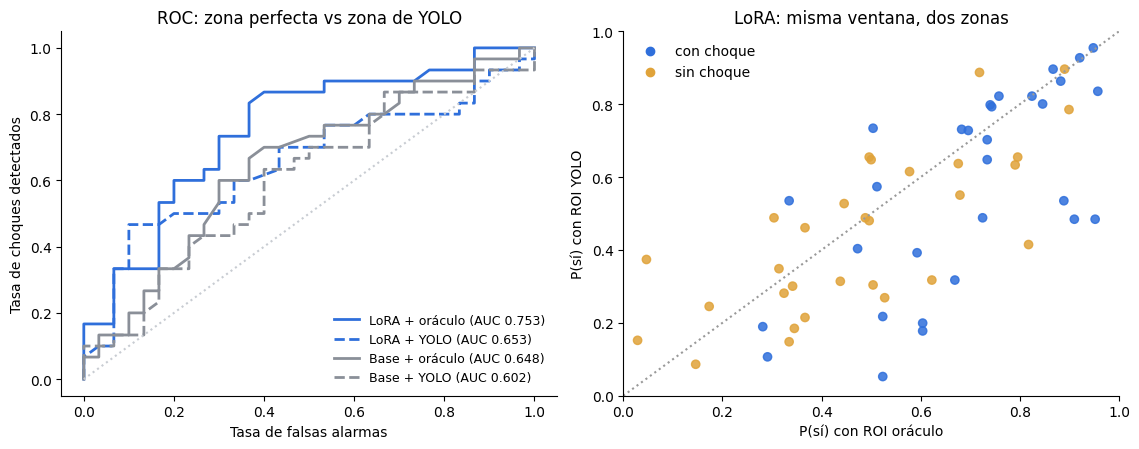

In [ ]:
# ===== 11. Figuras =====
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.6))
curvas = [(or_lora, 'LoRA + oráculo', '#2f6fdb', '-'), (res_lora_y, 'LoRA + YOLO', '#2f6fdb', '--')]
if COMPARAR_BASE:
    curvas += [(or_base, 'Base + oráculo', '#8a8f98', '-'), (res_base_y, 'Base + YOLO', '#8a8f98', '--')]
for res, n, c, ls in curvas:
    yy = (res.clase == 'positiva').astype(int)
    fpr, tpr, _ = roc_curve(yy, res.p_si)
    a1.plot(fpr, tpr, c=c, ls=ls, lw=2, label=f'{n} (AUC {roc_auc_score(yy, res.p_si):.3f})')
a1.plot([0, 1], [0, 1], ':', c='#c8ccd2'); a1.set(xlabel='Tasa de falsas alarmas', ylabel='Tasa de choques detectados',
                                               title='ROC: zona perfecta vs zona de YOLO')
a1.legend(frameon=False, fontsize=9); a1.spines[['top', 'right']].set_visible(False)

m = alinear(or_lora, res_lora_y)
col = np.where(m.clase_a == 'positiva', '#2f6fdb', '#e0a33a')
a2.scatter(m.p_si_a, m.p_si_c, c=col, s=36, alpha=.85)
a2.plot([0, 1], [0, 1], ':', c='#999')
a2.set(xlabel='P(sí) con ROI oráculo', ylabel='P(sí) con ROI YOLO', title='LoRA: misma ventana, dos zonas',
       xlim=(0, 1), ylim=(0, 1))
a2.scatter([], [], c='#2f6fdb', label='con choque'); a2.scatter([], [], c='#e0a33a', label='sin choque')
a2.legend(frameon=False); a2.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(f"{DIR_R3}/roc_oraculo_vs_yolo_{ROI_HASH}.png", dpi=200); plt.show()

## 12. Argumento de costo con números medidos

- **Paso 1** (YOLO + ByteTrack): throughput medido en R3a.
- **Paso 3** (LoRA): latencia medida aquí (`juzgar` + `prob_incidente`).
- **Tasa de alertas por cámara**: estas 60 ventanas están elegidas alrededor de choques, así que **no** sirven para estimarla. Se mantiene el supuesto del reporte (2 alertas/cámara/hora) y se muestra cómo cambia.

In [ ]:
# ===== 12. Costo =====
N_CAM, FPS = 100, 10
r3a_res = json.load(open(f"{DIR_R3}/resumen_r3a.json"))
img_s = max(x['img_por_s'] for x in r3a_res['bench'])
ms_track = r3a_res.get('ms_por_frame_con_tracking')
t4_yolo = N_CAM * FPS / img_s
lat_sup = float((res_lora_y.segundos + res_lora_y.segundos_p).median())
filas = []
for alertas_h in [1, 2, 5, 10]:
    t4_sup = N_CAM * alertas_h / 3600 * lat_sup
    filas.append({'alertas/cámara/hora': alertas_h, 'T4 paso 1 (YOLO)': round(t4_yolo, 2),
                  'T4 paso 3 (LoRA)': round(t4_sup, 2), 'T4 total': round(t4_yolo + t4_sup, 2)})
costo = pd.DataFrame(filas); display(costo)
print(f'YOLO: {img_s:.0f} img/s (mejor lote)' + (f', {ms_track:.1f} ms/frame con ByteTrack en lote 1' if ms_track else ''))
print(f'LoRA: {lat_sup:.1f} s por alerta (generar JSON + P(sí))')
costo.to_csv(f"{DIR_R3}/costo_{HUELLA}_{ROI_HASH}.csv", index=False)

,alertas/cámara/hora,T4 paso 1 (YOLO),T4 paso 3 (LoRA),T4 total
0,1,6.62,0.21,6.83
1,2,6.62,0.42,7.05
2,5,6.62,1.06,7.68
3,10,6.62,2.11,8.74


YOLO: 151 img/s (mejor lote)
LoRA: 7.6 s por alerta (generar JSON + P(sí))


In [ ]:
# ===== 13. Resumen para el reporte =====
pl = pruebas[0]
resumen = {'verificacion_dif_max': round(float(ver_df.dif.max()), 3),
           'tabla': tabla.to_dict(), 'cascada': casc.to_dict(), 'pruebas': pruebas,
           'costo': costo.to_dict('records'), 'fallos_fp16': PROB_FALLIDAS}
json.dump(resumen, open(f"{DIR_R3}/resumen_r3b_{ROI_HASH}.json", 'w'), indent=1, ensure_ascii=False, default=float)
print('=== Frases para el reporte ===')
print(f"• Con la ROI generada por YOLO + reglas, el LoRA obtiene AUC {pl['auc_a']:.3f} frente a {pl['auc_de']:.3f} con la ROI oráculo "
      f"(Δ {pl['dif']:+.3f}, IC95 {pl['ic_lo']:+.3f} a {pl['ic_hi']:+.3f}, DeLong p = {pl['p_delong']:.3g}).")
print(f"• Cascada completa (alerta de reglas Y LoRA): {casc.loc['choques detectados', 'Cascada (paso 2 Y LoRA)']} choques detectados, "
      f"{casc.loc['falsas alarmas', 'Cascada (paso 2 Y LoRA)']} falsas alarmas.")
print(f"• Costo con 2 alertas/cámara/hora: {costo.loc[costo['alertas/cámara/hora'] == 2, 'T4 total'].item()} T4 para 100 cámaras.")
print('\nArchivos en', DIR_R3, ':', sorted(os.listdir(DIR_R3)))

=== Frases para el reporte ===
• Con la ROI generada por YOLO + reglas, el LoRA obtiene AUC 0.653 frente a 0.753 con la ROI oráculo (Δ -0.101, IC95 -0.216 a +0.015, DeLong p = 0.0868).
• Cascada completa (alerta de reglas Y LoRA): 7/30 choques detectados, 0/30 falsas alarmas.
• Costo con 2 alertas/cámara/hora: 7.05 T4 para 100 cámaras.

Archivos en /content/drive/MyDrive/roadvision/resultados_qwen/r3_ebfa594f : ['cascada_ebfa594f.csv', 'cascada_ebfa594f_5bd154ce.csv', 'comparacion_oraculo_vs_yolo_ebfa594f.csv', 'comparacion_oraculo_vs_yolo_ebfa594f_5bd154ce.csv', 'costo_ebfa594f.csv', 'costo_ebfa594f_5bd154ce.csv', 'pruebas_pareadas_r3b_ebfa594f.csv', 'pruebas_pareadas_r3b_ebfa594f_5bd154ce.csv', 'recortes_oraculo_vs_yolo.png', 'recortes_oraculo_vs_yolo_5bd154ce.png', 'reglas_v1_vs_v2_test.csv', 'resumen_r3a.json', 'resumen_r3b.json', 'resumen_r3b_5bd154ce.json', 'roc_oraculo_vs_yolo.png', 'roc_oraculo_vs_yolo_5bd154ce.png', 'rois_yolo_ebfa594f.csv', 'rois_yolo_vs_oraculo.png', 'rois_y